In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [13]:
df = pd.read_csv("Telco Customer Churn.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies       

In [14]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)
df = df.dropna()

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [15]:
X = df[[ "tenure", "MonthlyCharges", "Contract", "InternetService" ]]
y = df["Churn"].map({ "No": 0, "Yes": 1})

numerical_features = [ "tenure", "MonthlyCharges"]
categorical_features = [ "Contract", "InternetService"]

In [16]:
preprocessor = ColumnTransformer(
    transformers=[ ( "num", StandardScaler(), numerical_features),
                ( "cat", OneHotEncoder(drop="first"), categorical_features ) ]
                )

In [17]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y )

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

Training samples: 5625
Testing samples: 1407


In [18]:
model = LogisticRegression( max_iter=1000, random_state=42 )
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

In [19]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.783226723525231
Precision: 0.6161616161616161
Recall   : 0.4893048128342246
F1-score : 0.5454545454545454



Confusion Matrix:
[[919 114]
 [191 183]]


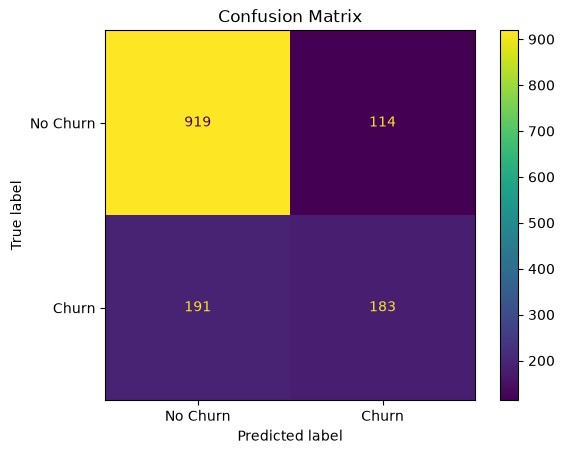

In [20]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

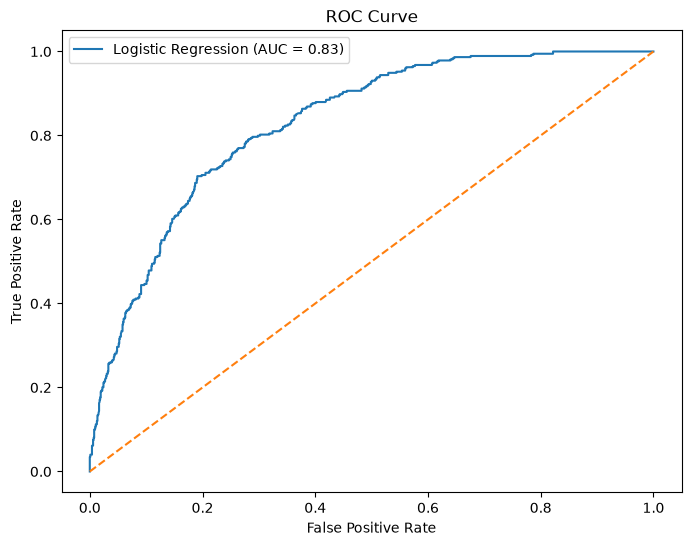

ROC-AUC Score: 0.8288278261229687


In [21]:
fpr, tpr, thresholds = roc_curve( y_test, y_probability)
auc = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(8, 6))

plt.plot( fpr, tpr,  label=f"Logistic Regression (AUC = {auc:.2f})")

plt.plot( [0, 1],  [0, 1], linestyle="--" )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC-AUC Score:", auc)